# Testing de Modelo Local (XGBoost) - Sin Overfitting

Este notebook evalua el modelo XGBoost **sin hacer trampas**: las carreras de test son las mas recientes y el modelo **nunca las ha visto** durante el entrenamiento.

### Split Temporal
- **Train**: Las 24 primeras carreras (por PRUEBA_ID)
- **Test**: Las 6 ultimas carreras - datos que el modelo JAMAS ha visto

### Modelo
XGBRegressor con regularizacion (L1/L2), max_depth=4 y early stopping.

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import spearmanr

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


### 1. Carga del Modelo y Datos

In [2]:
model_dict = joblib.load("../models/model_local.pkl")
model = model_dict["model"]
feature_cols = model_dict["feature_cols"]

print(f"Modelo cargado: {type(model).__name__}")
print(f"Features esperadas: {len(feature_cols)}")

df = pd.read_csv(r"../data/processed/trm_2025_azure_automl.csv")
print(f"Dataset total: {len(df)} filas, {df['PRUEBA_ID'].nunique()} carreras")


Modelo cargado: XGBRegressor
Features esperadas: 21
Dataset total: 1525 filas, 30 carreras


### 2. Split Temporal (mismo que en el entrenamiento)

In [3]:
pruebas_ordenadas = sorted(df["PRUEBA_ID"].unique())
split_idx = int(len(pruebas_ordenadas) * 0.8)
train_ids = pruebas_ordenadas[:split_idx]
test_ids = pruebas_ordenadas[split_idx:]

df_train = df[df["PRUEBA_ID"].isin(train_ids)]
df_test = df[df["PRUEBA_ID"].isin(test_ids)]

print(f"Train: {len(df_train)} filas ({len(train_ids)} carreras)")
print(f"Test:  {len(df_test)} filas ({len(test_ids)} carreras) - NUNCA VISTAS")
print(f"\nCarreras de TEST (PRUEBA_ID): {test_ids}")


Train: 1358 filas (24 carreras)
Test:  167 filas (6 carreras) - NUNCA VISTAS

Carreras de TEST (PRUEBA_ID): [1399, 1400, 1403, 1405, 1409, 1411]


### 3. Prediccion en la Carrera de Test con mas Participantes
Seleccionamos la carrera del set de test que tenga mas atletas.

In [4]:
carreras_test = df_test["PRUEBA_ID"].value_counts()
carrera_test = carreras_test.index[0]
participantes = carreras_test.iloc[0]
print(f"Carrera seleccionada: PRUEBA_ID={carrera_test} con {participantes} participantes")

df_carrera = df_test[df_test["PRUEBA_ID"] == carrera_test].copy()
X_test_carrera = df_carrera[feature_cols].fillna(0)
predicciones = model.predict(X_test_carrera)

resultados = df_carrera[["ATLETA_ID_HASH", "PUESTO_TARGET"]].copy()
resultados["PUNTOS_PREDICHOS"] = predicciones

resultados_ordenados = resultados.sort_values(by="PUNTOS_PREDICHOS", ascending=False)
resultados_ordenados["RANKING_PREDICHO"] = range(1, len(resultados_ordenados) + 1)

resultados_finales = resultados_ordenados.sort_values(by="PUESTO_TARGET")
print("\n--- TOP 15 de la carrera ---")
display(resultados_finales.head(15))


Carrera seleccionada: PRUEBA_ID=1400 con 48 participantes

--- TOP 15 de la carrera ---


,ATLETA_ID_HASH,PUESTO_TARGET,PUNTOS_PREDICHOS,RANKING_PREDICHO
1490,5e648e7918fd9a89,1,459.723145,3
205,433b4eac5757635b,2,455.015747,9
619,392f8f76ed9a46e1,3,149.925980,45
739,e4a2de7e250a2aa9,4,149.925980,46
1417,2cbffd05d43b0e16,5,503.714783,1
108,3f75f6055526daef,6,226.747559,23
239,37ce03f59741351d,7,149.925980,44
315,9c2e5f1048be201e,8,241.482513,22
77,e43207761255fb06,9,149.925980,34
808,fdeaafbe12115e29,10,188.975220,27


### 4. Metricas de la Carrera Individual

In [5]:
mae_pos = mean_absolute_error(resultados_finales["PUESTO_TARGET"], resultados_finales["RANKING_PREDICHO"])
corr, pval = spearmanr(resultados_finales["PUESTO_TARGET"], resultados_finales["RANKING_PREDICHO"])

print(f"MAE de Posicion: {mae_pos:.2f} puestos de diferencia de media")
print(f"Correlacion de Spearman: {corr:.3f} (p-value: {pval:.3e})")

for n in [3, 5, 10, 20]:
    if n > len(resultados_finales):
        continue
    real_set = set(resultados_finales.head(n).index)
    pred_set = set(resultados_ordenados.head(n).index)
    acc = len(real_set.intersection(pred_set))
    print(f"Top {n:2d}: {acc}/{n} atletas correctos ({acc/n*100:.0f}%)")


MAE de Posicion: 14.79 puestos de diferencia de media
Correlacion de Spearman: 0.126 (p-value: 3.929e-01)
Top  3: 1/3 atletas correctos (33%)
Top  5: 2/5 atletas correctos (40%)
Top 10: 3/10 atletas correctos (30%)
Top 20: 9/20 atletas correctos (45%)


### 5. Graficas de la Carrera Individual

C:\Users\mario\AppData\Local\Temp\ipykernel_5884\4067178659.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f"Top {n}" for n in tops], y=aciertos, ax=axes[1, 1], palette="viridis")


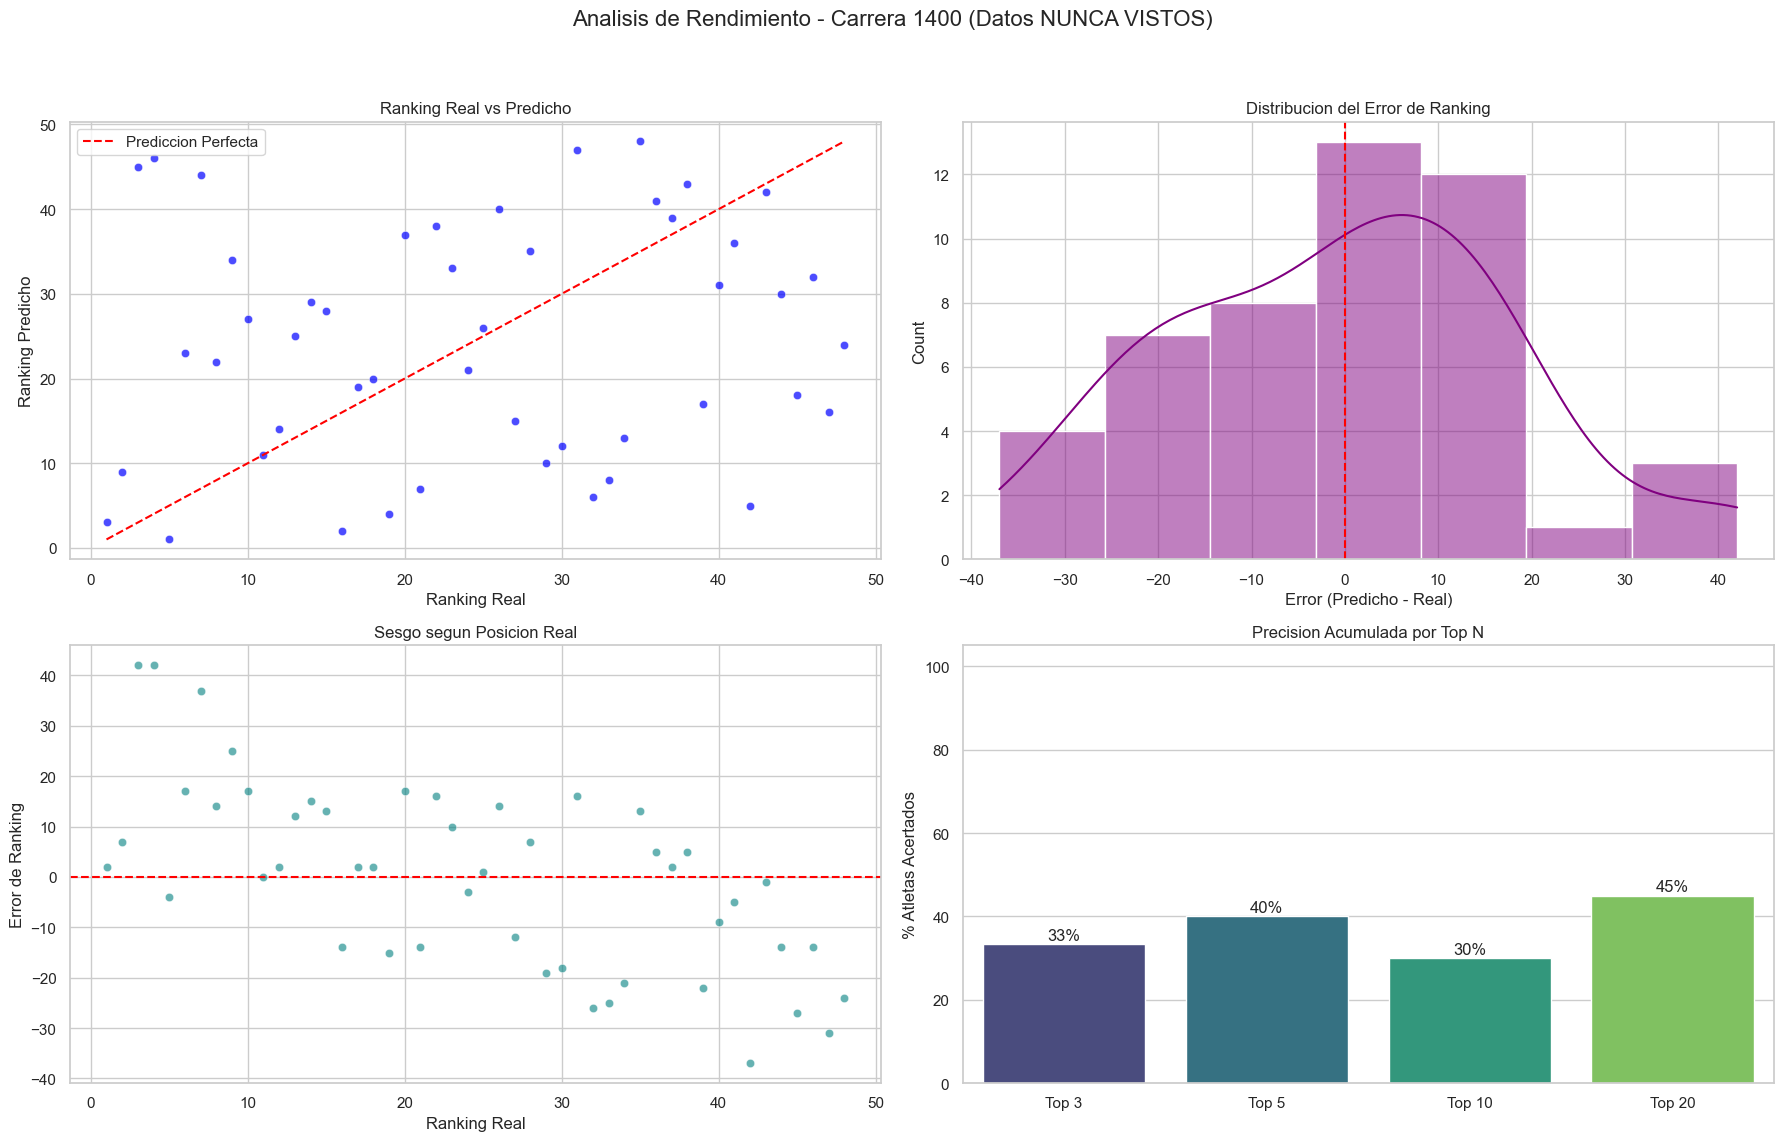

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(f"Analisis de Rendimiento - Carrera {carrera_test} (Datos NUNCA VISTOS)", fontsize=16)

sns.scatterplot(x="PUESTO_TARGET", y="RANKING_PREDICHO", data=resultados_finales, alpha=0.7, color="blue", ax=axes[0, 0])
max_rank = max(resultados_finales["PUESTO_TARGET"].max(), resultados_finales["RANKING_PREDICHO"].max())
axes[0, 0].plot([1, max_rank], [1, max_rank], color="red", linestyle="--", label="Prediccion Perfecta")
axes[0, 0].set_title("Ranking Real vs Predicho")
axes[0, 0].set_xlabel("Ranking Real")
axes[0, 0].set_ylabel("Ranking Predicho")
axes[0, 0].legend()

errores = resultados_finales["RANKING_PREDICHO"] - resultados_finales["PUESTO_TARGET"]
sns.histplot(errores, kde=True, ax=axes[0, 1], color="purple")
axes[0, 1].axvline(0, color="red", linestyle="--")
axes[0, 1].set_title("Distribucion del Error de Ranking")
axes[0, 1].set_xlabel("Error (Predicho - Real)")

sns.scatterplot(x=resultados_finales["PUESTO_TARGET"], y=errores, ax=axes[1, 0], alpha=0.6, color="teal")
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[1, 0].set_title("Sesgo segun Posicion Real")
axes[1, 0].set_xlabel("Ranking Real")
axes[1, 0].set_ylabel("Error de Ranking")

tops = [3, 5, 10, 20]
aciertos = []
for n in tops:
    if n > len(resultados_finales):
        aciertos.append(0)
        continue
    real_set = set(resultados_finales.head(n).index)
    pred_set = set(resultados_ordenados.head(n).index)
    aciertos.append(len(real_set.intersection(pred_set)) / n * 100)
sns.barplot(x=[f"Top {n}" for n in tops], y=aciertos, ax=axes[1, 1], palette="viridis")
for i, val in enumerate(aciertos):
    axes[1, 1].text(i, val + 1, f"{val:.0f}%", ha="center")
axes[1, 1].set_title("Precision Acumulada por Top N")
axes[1, 1].set_ylabel("% Atletas Acertados")
axes[1, 1].set_ylim(0, 105)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


### 6. Importancia de las Variables

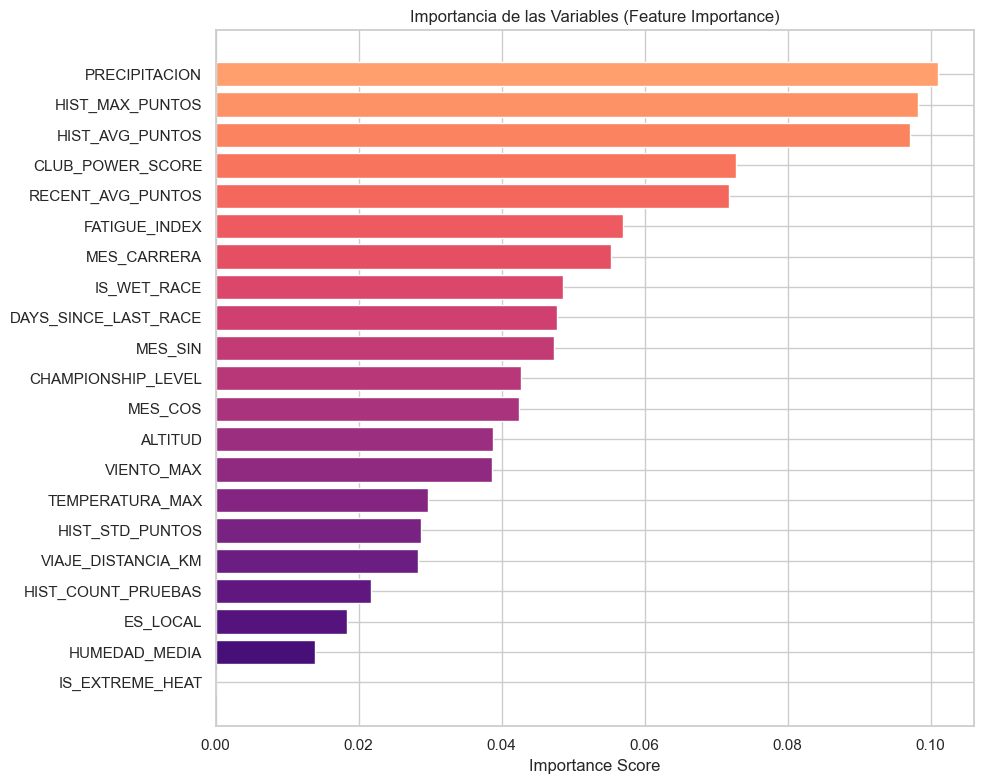

In [7]:
feat_imp = pd.DataFrame({"Feature": feature_cols, "Importance": model.feature_importances_})
feat_imp = feat_imp.sort_values(by="Importance", ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(feat_imp["Feature"], feat_imp["Importance"], color=plt.cm.magma(np.linspace(0.2, 0.8, len(feat_imp))))
ax.set_title("Importancia de las Variables (Feature Importance)")
ax.set_xlabel("Importance Score")
plt.tight_layout()
plt.show()


### 7. Evaluacion Global en TODAS las Carreras de Test
Iteramos por cada carrera del set de test y evaluamos la precision del ranking.

In [8]:
resultados_globales = []

for prueba_id in test_ids:
    df_c = df_test[df_test["PRUEBA_ID"] == prueba_id].copy()
    if len(df_c) < 5:
        continue
    
    X_c = df_c[feature_cols].fillna(0)
    pred = model.predict(X_c)
    
    res = df_c[["ATLETA_ID_HASH", "PUESTO_TARGET"]].copy()
    res["PUNTOS_PREDICHOS"] = pred
    res_pred = res.sort_values(by="PUNTOS_PREDICHOS", ascending=False)
    res_pred["RANKING_PREDICHO"] = range(1, len(res_pred) + 1)
    res_real = res_pred.sort_values(by="PUESTO_TARGET")
    
    mae = mean_absolute_error(res_real["PUESTO_TARGET"], res_real["RANKING_PREDICHO"])
    corr_val, _ = spearmanr(res_real["PUESTO_TARGET"], res_real["RANKING_PREDICHO"])
    
    n = min(10, len(res_real))
    real_set = set(res_real.head(n).index)
    pred_set = set(res_pred.head(n).index)
    top_acc = len(real_set.intersection(pred_set)) / n * 100
    
    resultados_globales.append({
        "PRUEBA_ID": prueba_id,
        "Participantes": len(df_c),
        "MAE_Posicion": round(mae, 2),
        "Spearman": round(corr_val, 3) if not np.isnan(corr_val) else 0,
        "TopN_Pct": round(top_acc, 1),
    })

df_global = pd.DataFrame(resultados_globales)
display(df_global)

print(f"\n--- RESUMEN GLOBAL (solo carreras NUNCA VISTAS) ---")
print(f"MAE promedio:      {df_global['MAE_Posicion'].mean():.2f} puestos")
print(f"Spearman promedio: {df_global['Spearman'].mean():.3f}")


,PRUEBA_ID,Participantes,MAE_Posicion,Spearman,TopN_Pct
0,1399,48,11.58,0.421,40.0
1,1400,48,14.79,0.126,30.0
2,1403,16,5.12,-0.188,60.0
3,1405,29,8.97,0.156,30.0
4,1409,21,4.67,0.474,60.0
5,1411,5,2.40,-0.800,100.0



--- RESUMEN GLOBAL (solo carreras NUNCA VISTAS) ---
MAE promedio:      7.92 puestos
Spearman promedio: 0.031


### 8. Deteccion de Overfitting: Train vs Test
Comparamos las metricas en datos de entrenamiento vs datos nunca vistos. Si hay una diferencia enorme, hay overfitting.

=== DETECCION DE OVERFITTING ===
Metrica                   Train       Test   Diferencia
-------------------------------------------------------
MAE (puntos)             177.24     225.16       +47.92
R2                        0.355      0.080       -0.275

VEREDICTO: El modelo NO tiene overfitting significativo. Ratio: 1.27x


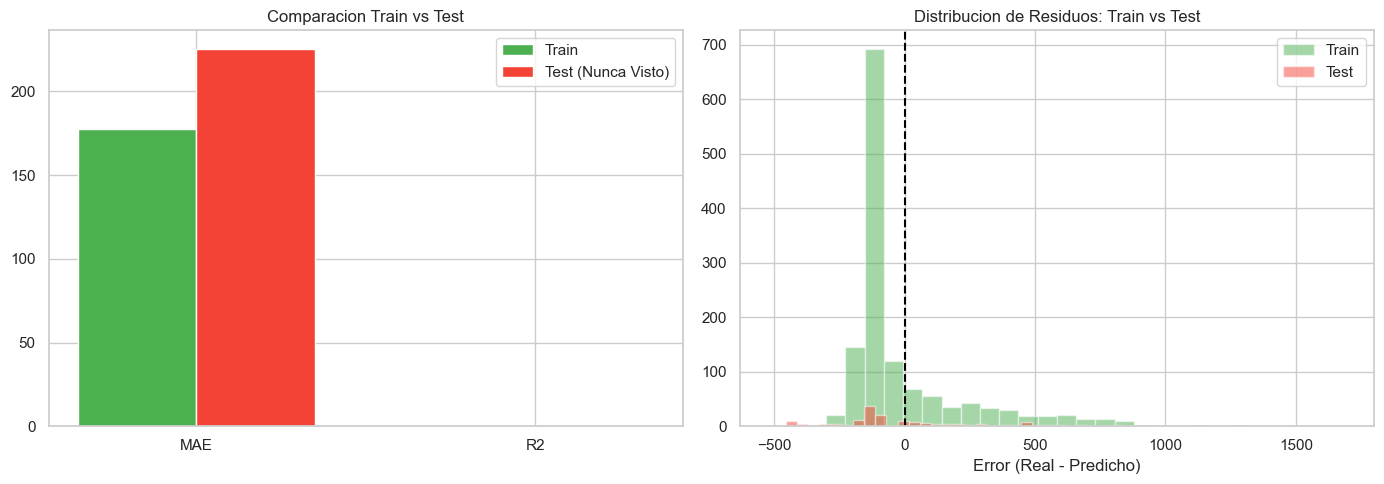

In [9]:
X_tr = df_train[feature_cols].fillna(0)
y_tr = df_train["PUNTOS_TARGET"]
y_tr_pred = model.predict(X_tr)
mae_train = mean_absolute_error(y_tr, y_tr_pred)
r2_train = r2_score(y_tr, y_tr_pred)

X_te = df_test[feature_cols].fillna(0)
y_te = df_test["PUNTOS_TARGET"]
y_te_pred = model.predict(X_te)
mae_test = mean_absolute_error(y_te, y_te_pred)
r2_test = r2_score(y_te, y_te_pred)

print("=== DETECCION DE OVERFITTING ===")
header = f"{'Metrica':<20} {'Train':>10} {'Test':>10} {'Diferencia':>12}"
print(header)
print("-" * 55)
print(f"{'MAE (puntos)':<20} {mae_train:>10.2f} {mae_test:>10.2f} {mae_test - mae_train:>+12.2f}")
print(f"{'R2':<20} {r2_train:>10.3f} {r2_test:>10.3f} {r2_test - r2_train:>+12.3f}")
print()

ratio = mae_test / mae_train if mae_train > 0 else float("inf")
if ratio < 1.5:
    print(f"VEREDICTO: El modelo NO tiene overfitting significativo. Ratio: {ratio:.2f}x")
elif ratio < 2.5:
    print(f"VEREDICTO: Hay overfitting MODERADO. Ratio: {ratio:.2f}x")
else:
    print(f"VEREDICTO: Hay overfitting SEVERO. Ratio: {ratio:.2f}x")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metricas = ["MAE", "R2"]
train_vals = [mae_train, r2_train]
test_vals = [mae_test, r2_test]
x = np.arange(len(metricas))
width = 0.35

axes[0].bar(x - width/2, train_vals, width, label="Train", color="#4CAF50")
axes[0].bar(x + width/2, test_vals, width, label="Test (Nunca Visto)", color="#F44336")
axes[0].set_title("Comparacion Train vs Test")
axes[0].set_xticks(x)
axes[0].set_xticklabels(metricas)
axes[0].legend()

residuos_train = y_tr - y_tr_pred
residuos_test = y_te - y_te_pred
axes[1].hist(residuos_train, bins=30, alpha=0.5, label="Train", color="#4CAF50")
axes[1].hist(residuos_test, bins=30, alpha=0.5, label="Test", color="#F44336")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Distribucion de Residuos: Train vs Test")
axes[1].set_xlabel("Error (Real - Predicho)")
axes[1].legend()

plt.tight_layout()
plt.show()
